# Notebook 03b — Comparação de janelas: 5 s, 12 s ou 24 s?

**Por que este notebook existe:** o Notebook 03 mostrou que a vibração tem um **ciclo lento de cerca de 10 s**. O grupo cronometrou a oscilação do ventilador (a cabeça indo de um lado ao outro e voltando) em **cerca de 12 s**. Com janelas de 5 s, cada janela pega só um pedaço desse ciclo. Uma janela forte, a seguinte fraca, e assim por diante. Isso faz o **mesmo ventilador normal** parecer diferente de uma janela para a outra.

**A pergunta:** uma janela que cobre o ciclo inteiro (12 s, ou duas voltas com 24 s) resolve isso **sem perder** a capacidade de separar normal e falha?

**A ideia em uma frase:** uma janela boa faz o Normal parecer sempre igual a ele mesmo e a falha parecer diferente do Normal.

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configurar | Quais janelas comparar |
| 2 | Carregar as bases | As mesmas bases de sempre |
| 3 | Calcular as 109 features em cada configuração | Uma tabela por janela |
| 4 | Teste de fase | A janela depende do ponto em que o corte começa? |
| 5 | Estabilidade do Normal | O Normal varia menos entre janelas? |
| 6 | Controle, ruído, separação e margem | A falha se destaca mais da variação natural? |
| 7 | Aplicar a regra de decisão | Qual janela usar daqui em diante |

## A regra de decisão (fixada antes de ver os resultados)

Para não escolher a janela "pelo resultado", o que seria adaptar demais aos dados, a regra foi decidida antes:

> **Fica a janela que cobre o ciclo medido (12 s; 24 s se 12 s não estabilizar o teste de fase), desde que ela (1) seja menos sensível à fase, (2) não piore o controle e (3) não piore a margem, em comparação com 5 s.**
>
> Se a janela do ciclo for pior, isso é algo a **investigar**, não um motivo para voltar a 5 s sem entender.

## Cuidados que valem para todo o notebook

* **Janelas maiores geram menos janelas.** Uma base de ~550 s tem 110 janelas de 5 s, mas só 45 de 12 s e 22 de 24 s. Com menos janelas, as medidas oscilam mais **por acaso**. O Passo 6 mede esse acaso para a comparação ser justa.
* **Só uma falha (a fita).** O resultado vale para ela. As falhas da nova coleta precisam confirmar.
* **A janela com sobreposição** ("12 s, passo 6 s") recupera parte das janelas, mas janelas vizinhas dividem metade dos dados. Por isso ela não entra no cálculo de autocorrelação e, no futuro, a divisão treino/teste precisa ser por blocos de tempo.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte.

## Passo 1 — Configuração

**O que buscamos:** os mesmos parâmetros do Notebook 02, mais o bloco **"JANELAS EM TESTE"**, que define as configurações comparadas.

* `CONFIGURACOES`: cada item é `(nome, tamanho da janela em s, passo em s)`. Quando o passo é igual ao tamanho, as janelas ficam lado a lado (sem sobreposição). Quando o passo é menor, elas se sobrepõem.
* `PERIODO_VARREDURA_S`: o tempo de ida e volta da cabeça do ventilador, cronometrado pelo grupo.

In [ ]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, rankdata
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

: 

In [ ]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta dos Notebooks 01 a 03)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\BASES_ROTULADAS")

# ----------------------------------------------------------------------
# QUEM É REFERÊNCIA E QUEM É COMPARADO
# ----------------------------------------------------------------------
CONDICOES_REFERENCIA = ["ventilador_normal"]
CONDICOES_COMPARADAS = None                    # None = todas as outras condições da pasta

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"

# ----------------------------------------------------------------------
# FEATURES (a mesma receita do Notebook 02)
# ----------------------------------------------------------------------
JANELA_S = 5                      # usado só como valor padrão das funções copiadas do Notebook 02
FAIXA_FFT_HZ = (5, 305)
LARGURA_FAIXA_HZ = 10
FAIXA_BUSCA_1X_HZ = (8, 30)
DESVIO_MAX_1X_HZ = 2.0
N_HARMONICAS = 3
TOLERANCIA_HARMONICA_HZ = 0.6

# ----------------------------------------------------------------------
# JANELAS EM TESTE
# ----------------------------------------------------------------------
PERIODO_VARREDURA_S = 12          # ida e volta da cabeça, cronometrado pelo grupo
CONFIGURACOES = [                 # (nome, tamanho da janela em s, passo em s)
    ("5 s", 5, 5),
    ("12 s", 12, 12),
    ("12 s, passo 6 s", 12, 6),
    ("24 s", 24, 24),
]
CONFIG_ATUAL = "5 s"              # a configuração usada até agora, base de comparação

# ----------------------------------------------------------------------
# CRITÉRIOS
# ----------------------------------------------------------------------
N_PERMUTACOES = 300               # sorteios usados para medir o nível de ruído do controle
PERCENTIL_RUIDO = 95              # o nível de ruído é este percentil do maior valor sorteado
N_MELHORES = 10                   # quantas features entram na "margem das melhores"
SEMENTE = 42                      # fixa o sorteio para o resultado ser sempre igual

# ----------------------------------------------------------------------
# TESTE DE FASE (Passo 4)
# ----------------------------------------------------------------------
PASSO_DESLIZANTE_S = 0.5          # a janela anda de meio em meio segundo
EIXO_FASE = "z"
DURACAO_GRAFICO_S = 120

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
CORES_CONFIG = {"5 s": "tab:orange", "12 s": "tab:blue", "12 s, passo 6 s": "tab:cyan", "24 s": "tab:purple"}

: 

## Passo 2 — Carregar as bases

**O que buscamos:** as mesmas bases dos notebooks anteriores. O código é o do Notebook 02, copiado sem alterações.

In [ ]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome 'fita_1g_vel_2' em condição ('fita_1g') e velocidade (2)."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N>, por exemplo 'fita_1g_vel_2'."
        )
    return encontrado["condicao"], int(encontrado["velocidade"])


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo), ordenados por condição e velocidade."""
    arquivos = sorted(Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({
            "base": nome,
            "condicao": condicao,
            "velocidade": velocidade,
            "linhas": len(bases[nome]),
            "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ,
        })
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "velocidade"]).set_index("base")
    bases = {nome: bases[nome] for nome in catalogo.index}
    return bases, catalogo


def definir_comparacoes(catalogo, condicoes_referencia, condicoes_comparadas=None):
    """Confere a referência e devolve a lista de condições que serão comparadas com ela."""
    existentes = sorted(catalogo["condicao"].unique())
    faltando = [c for c in condicoes_referencia if c not in existentes]
    if faltando:
        raise ValueError(f"Condição de referência não encontrada: {faltando}. Condições na pasta: {existentes}")
    if condicoes_comparadas is None:
        condicoes_comparadas = [c for c in existentes if c not in condicoes_referencia]
    faltando = [c for c in condicoes_comparadas if c not in existentes]
    if faltando:
        raise ValueError(f"Condição comparada não encontrada: {faltando}. Condições na pasta: {existentes}")
    if not condicoes_comparadas:
        raise ValueError(
            "Não há nenhuma condição para comparar com a referência. "
            "Coloque na pasta as bases da anomalia (por exemplo fita_1g_vel_1.csv)."
        )
    return list(condicoes_comparadas)


def resumir_catalogo(catalogo):
    """Número de bases e total de segundos por condição e velocidade."""
    return catalogo.groupby(["condicao", "velocidade"]).agg(bases=("linhas", "size"), duracao_s=("duracao_s", "sum"))


def avisar_velocidades_sem_referencia(catalogo, condicoes_referencia, condicoes_comparadas):
    """Avisa quando uma condição comparada tem uma velocidade que a referência não tem."""
    velocidades_ref = set(catalogo.loc[catalogo["condicao"].isin(condicoes_referencia), "velocidade"])
    for condicao in condicoes_comparadas:
        velocidades = set(catalogo.loc[catalogo["condicao"] == condicao, "velocidade"])
        sem_ref = sorted(velocidades - velocidades_ref)
        if sem_ref:
            print(f"ATENÇÃO: '{condicao}' tem as velocidades {sem_ref}, que a referência não tem. Elas ficarão sem comparação.")

: 

In [ ]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
condicoes_comparadas = definir_comparacoes(catalogo, CONDICOES_REFERENCIA, CONDICOES_COMPARADAS)
velocidades = sorted(catalogo["velocidade"].unique())

print(f"Referência: {CONDICOES_REFERENCIA}")
print(f"Comparadas: {condicoes_comparadas}")
avisar_velocidades_sem_referencia(catalogo, CONDICOES_REFERENCIA, condicoes_comparadas)
display(resumir_catalogo(catalogo))

: 

### Funções copiadas do Notebook 02

Cálculo das 99 features (tempo e FFT), das 10 de rotação, e da **separação** de −1 a +1 com o **controle** (primeira contra segunda metade do Normal). Nada foi alterado: o tamanho da janela já era um parâmetro (`janela_s`).

In [ ]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def colunas_fft_do_eixo(eixo):
    """Nomes das colunas de FFT de um eixo, na ordem das faixas."""
    return [f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}" for inicio, fim in faixas_de_frequencia()]


def calcular_features_e_espectros(df, janela_s=JANELA_S):
    """Corta a base em janelas sem sobreposição e calcula as features de cada janela.

    A última janela incompleta é descartada. Devolve (features, frequencias, espectros):
      features: uma linha por janela, com as colunas std_x, kurt_x, pico_x, ..., fft_005_015Hz_x, ...
      frequencias: eixo de frequências (Hz), de FAIXA_FFT_HZ[0] até FAIXA_FFT_HZ[1]
      espectros: magnitude de cada janela, no formato (janela, frequência, eixo)
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    colunas = {}
    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]

    # FFT com janela de Hanning; o fator 4/N compensa a energia que a janela remove
    janela_hanning = np.hanning(tamanho)[None, :, None]
    magnitude = np.abs(np.fft.rfft(janelas * janela_hanning, axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)

    for inicio, fim in faixas_de_frequencia():
        na_faixa = (frequencias >= inicio) & (frequencias < fim)
        maximo_da_faixa = magnitude[:, na_faixa, :].max(axis=1)     # (janela, eixo)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo_da_faixa[:, k]

    no_intervalo = (frequencias >= FAIXA_FFT_HZ[0]) & (frequencias < FAIXA_FFT_HZ[1])
    return pd.DataFrame(colunas), frequencias[no_intervalo], magnitude[:, no_intervalo, :]


def analisar_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Calcula as features de todas as bases e junta numa só tabela.

    Devolve (features, frequencias, espectros_por_base). A tabela tem as colunas
    base, condicao, velocidade e janela (posição da janela dentro da base), mais as 99 features.
    """
    tabelas, espectros_por_base, frequencias = [], {}, None
    for nome, df in bases.items():
        features, frequencias, espectros = calcular_features_e_espectros(df, janela_s)
        features.insert(0, "janela", np.arange(len(features)))
        features.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        features.insert(0, "condicao", catalogo.loc[nome, "condicao"])
        features.insert(0, "base", nome)
        tabelas.append(features)
        espectros_por_base[nome] = espectros
    return pd.concat(tabelas, ignore_index=True), frequencias, espectros_por_base

: 

In [ ]:
def estimar_f1x(frequencias, espectros):
    """Rotação 1X de cada janela, em duas passadas.

    1ª passada: pico da soma dos três eixos dentro de FAIXA_BUSCA_1X_HZ, janela por janela.
    A mediana dessas janelas é a rotação típica da base.
    2ª passada: repete a busca, mas só a até DESVIO_MAX_1X_HZ da rotação típica. Isso evita que, numa
    anomalia forte, o pico do 2X ou de outra frequência seja confundido com o 1X.
    """
    soma_dos_eixos = espectros.sum(axis=2)                                         # (janela, frequência)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    primeira = frequencias[na_faixa][soma_dos_eixos[:, na_faixa].argmax(axis=1)]
    tipica = np.median(primeira)
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    return frequencias[perto][soma_dos_eixos[:, perto].argmax(axis=1)]


def medir_amplitudes_harmonicas(frequencias, espectros, f1x, n_harmonicas, tolerancia_hz):
    """Amplitude de 1X, 2X, ... em cada janela e eixo: o maior pico a até tolerancia_hz de k vezes o 1X."""
    colunas = {}
    for k in range(1, n_harmonicas + 1):
        alvo = k * f1x                                                           # (janela,)
        perto = np.abs(frequencias[None, :] - alvo[:, None]) <= tolerancia_hz     # (janela, frequência)
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto, espectros[:, :, j], 0.0).max(axis=1)
    return pd.DataFrame(colunas)


def adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base):
    """Acrescenta à tabela a rotação (f1x_hz) e as amplitudes amp_1x_x, amp_2x_x, ... de cada janela."""
    features = features.drop(columns=[c for c in features.columns if c.startswith("amp_") or c == "f1x_hz"])
    partes = []
    for nome, grupo in features.groupby("base", sort=False):
        espectros = espectros_por_base[nome]
        f1x = estimar_f1x(frequencias, espectros)
        amplitudes = medir_amplitudes_harmonicas(frequencias, espectros, f1x, N_HARMONICAS, TOLERANCIA_HARMONICA_HZ)
        amplitudes.insert(0, "f1x_hz", f1x)
        amplitudes.index = grupo.index
        partes.append(amplitudes)
    return features.join(pd.concat(partes))

: 

In [ ]:
EPS = 1e-12   # evita divisão por zero nas razões


def selecionar_janelas(features, condicoes, velocidade):
    """Janelas de uma lista de condições numa velocidade."""
    return features[features["condicao"].isin(condicoes) & (features["velocidade"] == velocidade)]


def calcular_separacao(grupo_a, grupo_b, colunas):
    """Separação (de -1 a +1) entre dois grupos de janelas, feature por feature.

    Positivo significa que o grupo_a tem valores maiores que o grupo_b. É a área sob a curva ROC
    reescalada (2 x AUC - 1), calculada pelas posições (ranks) dos valores.
    """
    n_a, n_b = len(grupo_a), len(grupo_b)
    if n_a == 0 or n_b == 0:
        return pd.Series(np.nan, index=colunas)
    valores = np.vstack([grupo_a[colunas].to_numpy(), grupo_b[colunas].to_numpy()])
    postos = rankdata(valores, axis=0)
    auc = (postos[:n_a].sum(axis=0) - n_a * (n_a + 1) / 2) / (n_a * n_b)
    return pd.Series(2 * auc - 1, index=colunas)


def dividir_ao_meio(janelas):
    """Divide cada base em primeira e segunda metade (pela ordem das janelas) e junta as metades.

    Devolve (primeira_metade, segunda_metade).
    """
    primeiras, segundas = [], []
    for _, grupo in janelas.groupby("base", sort=False):
        grupo = grupo.sort_values("janela")
        meio = len(grupo) // 2
        primeiras.append(grupo.iloc[:meio])
        segundas.append(grupo.iloc[len(grupo) - meio:])
    return pd.concat(primeiras), pd.concat(segundas)


def calcular_separacao_controle(referencia, colunas):
    """Separação entre a segunda e a primeira metade da referência (variação natural do normal)."""
    primeira, segunda = dividir_ao_meio(referencia)
    return calcular_separacao(segunda, primeira, colunas)


def juntar_espectros(espectros_por_base, janelas):
    """Empilha os espectros das janelas escolhidas. Formato (janela, frequência, eixo)."""
    partes = [espectros_por_base[base][grupo["janela"].to_numpy()] for base, grupo in janelas.groupby("base", sort=False)]
    return np.concatenate(partes, axis=0)

: 

## Passo 3 — As 109 features em cada configuração de janela

**O que buscamos:** a mesma tabela de features do Notebook 02, uma vez para cada janela em teste.

**O que o código faz:**

1. **Sem sobreposição** (5 s, 12 s, 24 s): corta cada base em janelas lado a lado, exatamente como o Notebook 02, só mudando o tamanho.
2. **Com sobreposição** ("12 s, passo 6 s"): faz dois cortes de 12 s, um começando em 0 s e outro em 6 s, e junta os dois em ordem de tempo. O resultado é uma janela nova a cada 6 s.
3. Calcula também as 10 features de rotação. Com janelas maiores a FFT tem **mais resolução** (0,2 Hz com 5 s; 0,08 Hz com 12 s), o que melhora a estimativa do 1X.

A tabela mostra quantas janelas cada base tem em cada configuração.

In [ ]:
def calcular_features_desde(bases, catalogo, janela_s, inicio_s):
    """Features de todas as bases, com janelas lado a lado começando em inicio_s (o trecho antes é ignorado)."""
    amostras_iniciais = int(round(inicio_s * TAXA_AMOSTRAGEM_HZ))
    bases_cortadas = {nome: df.iloc[amostras_iniciais:].reset_index(drop=True) for nome, df in bases.items()}
    features, frequencias, espectros_por_base = analisar_todas_as_bases(bases_cortadas, catalogo, janela_s)
    features = adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base)
    features.insert(4, "inicio_s", inicio_s + features["janela"] * janela_s)
    return features


def calcular_features_da_configuracao(bases, catalogo, janela_s, passo_s):
    """Features com janela de janela_s andando de passo_s em passo_s.

    Sem sobreposição (passo = janela) é o mesmo corte do Notebook 02. Com sobreposição, junta os cortes que
    começam em 0, passo, 2 x passo, ... e renumera as janelas pela ordem no tempo.
    """
    partes = [calcular_features_desde(bases, catalogo, janela_s, inicio) for inicio in np.arange(0, janela_s, passo_s)]
    features = pd.concat(partes, ignore_index=True).sort_values(["base", "inicio_s"]).reset_index(drop=True)
    features["janela"] = features.groupby("base").cumcount()
    return features

: 

In [ ]:
features_por_config = {}
for nome, janela_s, passo_s in CONFIGURACOES:
    features_por_config[nome] = calcular_features_da_configuracao(bases, catalogo, janela_s, passo_s)

COLUNAS_TEMPO = [f"{tipo}_{eixo}" for tipo in ("std", "kurt", "pico") for eixo in EIXOS]
COLUNAS_FFT = [coluna for eixo in EIXOS for coluna in colunas_fft_do_eixo(eixo)]
COLUNAS_ROTACAO = [f"amp_{k}x_{eixo}" for k in range(1, N_HARMONICAS + 1) for eixo in EIXOS] + ["f1x_hz"]
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO

resumo_janelas = pd.DataFrame({nome: f.groupby("base").size() for nome, f in features_por_config.items()})
print(f"{len(COLUNAS_TODAS)} features em cada configuração. Janelas por base:")
display(resumo_janelas)

: 

## Passo 4 — Teste de fase: o valor da janela depende de onde ela começa?

**O que buscamos:** o teste mais direto do problema. Se uma janela cobre o ciclo inteiro, **não importa em que momento ela começa**: o valor é sempre parecido. Se cobre só um pedaço, o valor muda conforme o pedaço que pegou.

**Como:** fazemos a janela "andar" pelo sinal de meio em meio segundo e calculamos o desvio padrão do eixo z em cada posição. Assim vemos o valor que **todas as janelas possíveis** teriam, em vez de só as que o corte escolheu.

**Como ler o gráfico:**

* **Linha que ondula muito:** o valor da janela depende do ponto de início. Isso é ruim.
* **Linha quase reta:** a janela é **insensível à fase**. Isso é o que queremos.

**Como ler a tabela:** a "variação" é o desvio padrão dessa linha dividido pela média, em porcentagem. Quanto menor, menos o corte importa.

**Atenção:** uma janela maior sempre varia um pouco menos, só por ter mais amostras. Se o sinal fosse só barulho, ir de 5 s para 12 s reduziria a variação pelo fator √(5/12) ≈ 0,65. A coluna **"esperado só pelo tamanho"** mostra esse valor. **Se a variação real ficar bem abaixo do esperado, a diferença vem do ciclo** que deixou de ser cortado ao meio.

In [10]:
def calcular_intensidade_deslizante(df, janela_s, passo_s=PASSO_DESLIZANTE_S, eixo=EIXO_FASE):
    """Desvio padrão de uma janela de janela_s que anda de passo_s em passo_s. Devolve (inicio_s, valores)."""
    sinal = df[eixo].to_numpy()
    tamanho, passo = int(janela_s * TAXA_AMOSTRAGEM_HZ), int(passo_s * TAXA_AMOSTRAGEM_HZ)
    inicios = np.arange(0, len(sinal) - tamanho + 1, passo)
    valores = np.array([sinal[i:i + tamanho].std(ddof=1) for i in inicios])
    return inicios / TAXA_AMOSTRAGEM_HZ, valores


def medir_sensibilidade_a_fase(bases, tamanhos_s):
    """Por base e tamanho de janela: variação (%) do valor da janela conforme o ponto onde ela começa."""
    linhas = {}
    for nome, df in bases.items():
        linhas[nome] = {}
        for janela_s in tamanhos_s:
            _, valores = calcular_intensidade_deslizante(df, janela_s)
            linhas[nome][f"{janela_s} s"] = 100 * valores.std() / valores.mean()
    return pd.DataFrame(linhas).T


def plotar_teste_de_fase(bases, nomes_bases, tamanhos_s, duracao_s=DURACAO_GRAFICO_S):
    """Valor da janela conforme o ponto onde ela começa, uma linha por tamanho de janela."""
    fig, axs = plt.subplots(len(nomes_bases), 1, figsize=(14, 3 * len(nomes_bases)), squeeze=False)
    for ax, nome in zip(axs[:, 0], nomes_bases):
        for janela_s in tamanhos_s:
            inicio, valores = calcular_intensidade_deslizante(bases[nome], janela_s)
            ax.plot(inicio, valores, linewidth=1.5, color=CORES_CONFIG.get(f"{janela_s} s", None), label=f"janela de {janela_s} s")
        ax.set_xlim(0, duracao_s)
        ax.set_title(f"{nome} — desvio padrão de {EIXO_FASE} da janela que começa em cada instante", fontsize=11, fontweight="bold")
        ax.set_ylabel(UNIDADE)
        ax.legend(fontsize=9, loc="upper right")
    axs[-1, 0].set_xlabel("Instante em que a janela começa (s)")
    plt.tight_layout()
    plt.show()

Variação do valor da janela conforme o ponto de início (%), desvio padrão do eixo z


,5 s,12 s,24 s,12 s esperado só pelo tamanho,24 s esperado só pelo tamanho
fita_1g_vel_1,7.0,4.3,3.5,4.5,3.2
fita_1g_vel_2,9.5,4.5,4.4,6.1,4.3
fita_1g_vel_3,34.0,15.8,13.0,21.9,15.5
ventilador_normal_vel_1,11.5,6.9,5.6,7.4,5.2
ventilador_normal_vel_2,6.3,4.3,4.2,4.1,2.9
ventilador_normal_vel_3,9.2,3.2,2.2,5.9,4.2


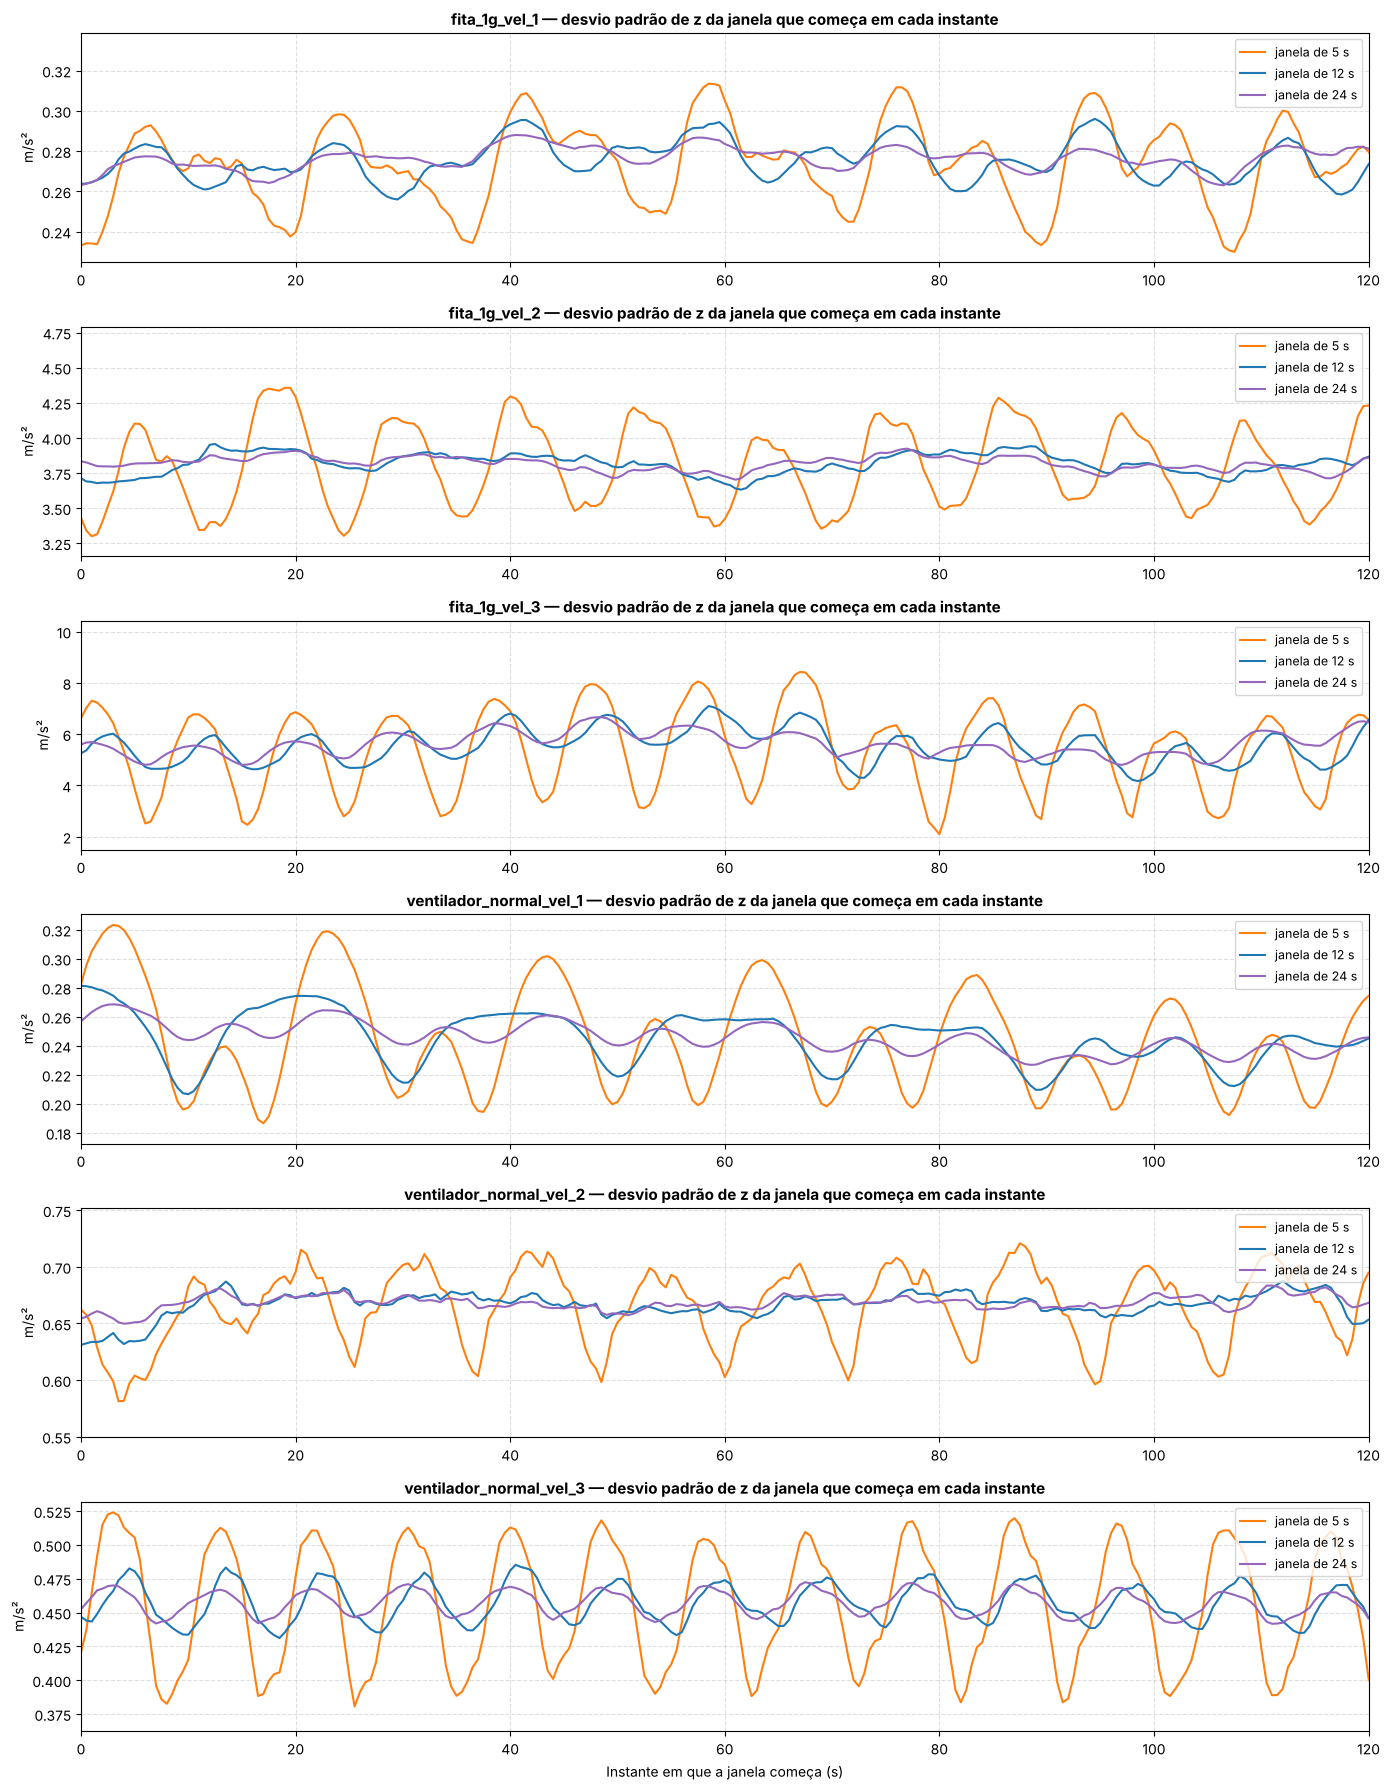

In [11]:
TAMANHOS_TESTE = sorted({janela_s for _, janela_s, _ in CONFIGURACOES})

sensibilidade = medir_sensibilidade_a_fase(bases, TAMANHOS_TESTE)
menor = TAMANHOS_TESTE[0]
for janela_s in TAMANHOS_TESTE[1:]:
    sensibilidade[f"{janela_s} s esperado só pelo tamanho"] = sensibilidade[f"{menor} s"] * np.sqrt(menor / janela_s)
print("Variação do valor da janela conforme o ponto de início (%), desvio padrão do eixo", EIXO_FASE)
display(sensibilidade.round(1))

plotar_teste_de_fase(bases, sorted(bases), TAMANHOS_TESTE)

### Conclusões do Passo 4 (nesta execução)

**A janela de 12 s reduz bastante a dependência da fase, mas não a elimina.**

* **No gráfico:** a linha laranja (5 s) sobe e desce com força a cada ciclo em todas as bases. A azul (12 s) e a roxa (24 s) ficam bem mais retas.
* **Na tabela:** com 12 s, a variação cai em todas as bases, por exemplo `ventilador_normal_vel_3` de 9,2% para 3,2% e `fita_1g_vel_3` de 34% para 16%.
* **Efeito do ciclo, não só da média:** em 4 das 6 bases a queda vai **além** do esperado só pelo tamanho. Em `ventilador_normal_vel_3` o esperado seria 5,9% e o real foi 3,2%. Em `fita_1g_vel_2`, 6,1% esperado e 4,5% real. A exceção é `ventilador_normal_vel_2` (4,3% real, 4,1% esperado), onde o ciclo já era fraco.
* **O que ainda ondula:** na Vel 3 (normal e fita), a linha de 12 s ainda tem ondas visíveis. É provável que seja porque **o ciclo dessas bases é de ~9,5 s** (Notebook 03), e não de 12 s. Uma janela de 12 s não fecha um número inteiro de ciclos de 9,5 s, então sobra um resto que oscila. **Isso sugere que o período da varredura muda com a velocidade**, e reforça a necessidade de cronometrar as 3 velocidades.
* **24 s** reduz um pouco mais, mas quase sempre perto do esperado só pelo tamanho. O ganho extra é principalmente de "mais média", não de resolver melhor o ciclo.

## Passo 5 — Estabilidade do Normal: o efeito é do ciclo ou só do tamanho?

**O que buscamos:** confirmar que a janela maior resolve o **ciclo**, e não apenas "faz mais média".

**O ponto delicado:** qualquer média feita com mais dados varia menos. Se o sinal não tivesse ciclo nenhum, só barulho, aumentar a janela de 5 para 12 s reduziria a variação por um fator de √(5/12) ≈ 0,65. É uma regra estatística: a variação de uma média cai com a raiz do número de amostras.

**O teste:**

* **"variação típica"** é o quanto cada feature varia entre as janelas de uma mesma base do Normal (desvio ÷ média, em %, mediana de todas as features e bases).
* **"esperado só pelo tamanho"** é quanto ela deveria cair **só por causa da raiz**, partindo da variação com 5 s.
* **Se a variação real cair bem mais do que o esperado,** a diferença vem do ciclo que deixou de ser cortado ao meio.

**Autocorrelação:** com 5 s, o Notebook 03 achou valores negativos (janela forte seguida de fraca). Com uma janela do tamanho do ciclo, ela deve ir para **perto de zero**. Não é calculada para a janela com sobreposição, porque vizinhas que dividem dados são parecidas por construção.

In [12]:
def calcular_variacao_dentro_da_base(features, colunas, condicoes):
    """Coeficiente de variação (desvio / média, %) de cada feature dentro de cada base das condições dadas."""
    janelas = features[features["condicao"].isin(condicoes)]
    positivas = [c for c in colunas if (janelas[c] > 0).all()]
    por_base = janelas.groupby("base")[positivas]
    return 100 * por_base.std() / por_base.mean()


def calcular_autocorrelacao(features, colunas, condicoes):
    """Autocorrelação de lag 1 de cada feature dentro de cada base (só janelas sem sobreposição fazem sentido)."""
    janelas = features[features["condicao"].isin(condicoes)]
    return janelas.groupby("base").apply(
        lambda g: g.sort_values("janela")[colunas].apply(lambda s: s.autocorr(lag=1)), include_groups=False)


def resumir_estabilidade(features_por_config, colunas, condicoes, config_base=CONFIG_ATUAL):
    """Por configuração: variação típica dentro da base, o que se esperaria só por ter janelas maiores, e autocorrelação."""
    janela_base = dict((n, j) for n, j, _ in CONFIGURACOES)[config_base]
    variacao_base = calcular_variacao_dentro_da_base(features_por_config[config_base], colunas, condicoes).median(axis=1).median()
    linhas = {}
    for nome, janela_s, passo_s in CONFIGURACOES:
        features = features_por_config[nome]
        variacao = calcular_variacao_dentro_da_base(features, colunas, condicoes).median(axis=1).median()
        linha = {
            "variação típica (%)": variacao,
            "esperado só pelo tamanho (%)": variacao_base * np.sqrt(janela_base / janela_s),
        }
        linha["autocorrelação mediana"] = (calcular_autocorrelacao(features, colunas, condicoes).median(axis=1).median()
                                           if passo_s == janela_s else np.nan)
        linhas[nome] = linha
    return pd.DataFrame(linhas).T

In [13]:
print("Estabilidade do Normal (todas as features, todas as velocidades):")
display(resumir_estabilidade(features_por_config, COLUNAS_TODAS, CONDICOES_REFERENCIA).round(2))

Estabilidade do Normal (todas as features, todas as velocidades):


,variação típica (%),esperado só pelo tamanho (%),autocorrelação mediana
5 s,36.19,36.19,-0.11
12 s,25.12,23.36,0.25
"12 s, passo 6 s",25.24,23.36,NaN
24 s,17.47,16.52,0.25


### Conclusões do Passo 5 (nesta execução)

**Olhando as 109 features juntas, a queda da variação é quase só a esperada pelo tamanho da janela.**

* A variação típica do Normal foi de **36% (5 s) para 25% (12 s)**, quando o esperado só pelo tamanho era 23%. Para 24 s: 17% contra 17% esperado.
* **Por que isso parece contradizer o Passo 4?** O Passo 4 olhou só o desvio padrão do eixo z, que é a feature que **mais** sente o ciclo. A mediana das 109 é dominada pelas **90 de FFT**, que medem o máximo de uma faixa estreita de 10 Hz e são naturalmente "barulhentas". Para elas, o barulho de janela para janela pesa mais que o ciclo. **O ciclo é real, mas afeta mais as features de intensidade (tempo e 1X) do que o espectro fino.**
* **A autocorrelação mudou de sinal:** de **−0,11 com 5 s** (vai e vem do ciclo) para **+0,25 com 12 s e 24 s**. Positiva significa que **janelas vizinhas são parecidas**, o sinal de uma **mudança lenta ao longo da gravação** (por exemplo, aquecimento do motor). Com 5 s, essa deriva lenta ficava escondida atrás do vai e vem do ciclo. Com janelas maiores, o ciclo some e a deriva aparece.

## Passo 6 — Controle, ruído, separação e margem

**O que buscamos:** saber se a falha se destaca **mais** da variação natural do Normal com a janela nova.

**As medidas, uma por uma:**

| Medida | O que é | Melhor quando |
| --- | --- | --- |
| **teto do controle** | A maior separação entre a 1ª e a 2ª metade do Normal (como no Notebook 02). Mostra o quanto o Normal muda dentro dele mesmo. | menor |
| **nível de ruído** | O teto que apareceria **só por acaso**, com o mesmo número de janelas. | (referência) |
| **controle acima do ruído** | teto − ruído. Quanto o Normal muda **além do acaso**: deriva, ciclo, aquecimento. | menor (perto de 0 ou negativo) |
| **separação das melhores** | Mediana da separação das 10 melhores features. Perto de 1 = a falha já separa quase perfeitamente. | maior |
| **features acima do teto** | Quantas das 109 separam a falha mais do que o Normal se separa dele mesmo (como no Notebook 02). | maior |
| **margem das melhores** | Mediana de (separação − teto) nas 10 melhores features. É quanto a falha se destaca acima da variação natural. | maior |

**Por que o "nível de ruído" é necessário (o cuidado mais importante deste notebook):**

O teto do controle é **o maior valor entre 109 features**. Com menos janelas, cada separação oscila mais por acaso, e o maior deles sobe. Com 22 janelas por base (24 s), o teto sobe mesmo que o Normal seja perfeitamente estável. Comparar o teto direto **puniria injustamente as janelas maiores**.

**Como medimos o acaso:** sorteamos as janelas do Normal em dois grupos (sem respeitar a ordem do tempo), calculamos a maior separação, e repetimos 300 vezes. Num sorteio não existe deriva nem ciclo, então o que aparece é **só acaso**. O nível de ruído é o valor que o acaso só supera 5% das vezes.

* **Exemplo:** se o teto é 0,60 e o ruído é 0,45, o Normal muda 0,15 **além do acaso** (deriva real). Se o teto é 0,40 e o ruído é 0,45, tudo o que vemos no controle pode ser acaso (−0,05).

**Atenção à "margem das melhores" (duas armadilhas):**

1. **Saturação.** Se a fita já separa quase perfeitamente com 5 s (separação das melhores perto de 1), não há como a separação subir. A margem só pode mudar pelo teto.
2. **A margem usa o teto bruto, que inclui o acaso.** Como o teto sobe com menos janelas, a margem **cai com menos janelas mesmo que nada mude no ventilador**. Compare sempre a queda do teto com a subida do nível de ruído antes de concluir.

**Também há saturação no controle:** se o teto do controle for perto de 1, as duas metades do Normal já são completamente diferentes com qualquer janela (deriva forte). Aí "controle acima do ruído" passa a medir só o ruído (1 − ruído) e não diz nada sobre a janela.

In [14]:
def calcular_nivel_de_ruido(referencia, colunas, n_permutacoes=N_PERMUTACOES, percentil=PERCENTIL_RUIDO, semente=SEMENTE):
    """Maior separação que aparece só por acaso, sorteando as janelas do Normal em duas metades.

    Em cada sorteio, as janelas são divididas ao acaso em dois grupos do mesmo tamanho das metades do controle,
    e anotamos a maior |separação| entre as features. O nível de ruído é o percentil desses máximos.
    """
    gerador = np.random.default_rng(semente)
    primeira, segunda = dividir_ao_meio(referencia)
    todas = pd.concat([primeira, segunda])
    n_primeira = len(primeira)
    maximos = []
    for _ in range(n_permutacoes):
        ordem = gerador.permutation(len(todas))
        grupo_a, grupo_b = todas.iloc[ordem[:n_primeira]], todas.iloc[ordem[n_primeira:]]
        maximos.append(calcular_separacao(grupo_b, grupo_a, colunas).abs().max())
    return np.percentile(maximos, percentil)


def comparar_configuracoes(features_por_config, condicoes_ref, condicao, colunas, velocidades):
    """Por configuração e velocidade: controle, ruído, separação e margem."""
    linhas = []
    for nome, _, _ in CONFIGURACOES:
        features = features_por_config[nome]
        for velocidade in velocidades:
            ref = selecionar_janelas(features, condicoes_ref, velocidade)
            comp = selecionar_janelas(features, [condicao], velocidade)
            if len(ref) == 0 or len(comp) == 0:
                continue
            separacao = calcular_separacao(comp, ref, colunas).abs()
            controle = calcular_separacao_controle(ref, colunas).abs()
            teto = controle.max()
            ruido = calcular_nivel_de_ruido(ref, colunas)
            melhores = separacao.sort_values(ascending=False).head(N_MELHORES)
            linhas.append({
                "configuracao": nome, "velocidade": velocidade,
                "janelas (ref + anomalia)": len(ref) + len(comp),
                "teto do controle": teto,
                "nível de ruído": ruido,
                "controle acima do ruído": teto - ruido,
                "separação das melhores": melhores.median(),
                "features acima do teto": int((separacao > teto).sum()),
                "margem das melhores": (melhores - teto).median(),
            })
    tabela = pd.DataFrame(linhas)
    tabela["configuracao"] = pd.Categorical(tabela["configuracao"], categories=[n for n, _, _ in CONFIGURACOES], ordered=True)
    return tabela.set_index(["velocidade", "configuracao"]).sort_index()

In [15]:
comparacoes = {}
for condicao in condicoes_comparadas:
    comparacoes[condicao] = comparar_configuracoes(features_por_config, CONDICOES_REFERENCIA, condicao, COLUNAS_TODAS, velocidades)
    print(f"==================== {condicao} vs. referência ====================")
    display(comparacoes[condicao].round(2))

==================== fita_1g vs. referência ====================


janelas (ref + anomalia)  teto do controle  \
velocidade configuracao                                                  
1          5 s                                   232              0.99   
           12 s                                   96              1.00   
           12 s, passo 6 s                       191              1.00   
           24 s                                   48              1.00   
2          5 s                                   224              0.73   
           12 s                                   92              0.87   
           12 s, passo 6 s                       184              0.81   
           24 s                                   45              0.95   
3          5 s                                   220              0.49   
           12 s                                   91              0.78   
           12 s, passo 6 s                       181              0.65   
           24 s                                   45              0.90   

                            nível de ruído  controle acima do ruído  \
velocidade configuracao                                               
1          5 s                        0.35                     0.64   
           12 s                       0.54                     0.46   
           12 s, passo 6 s            0.39                     0.60   
           24 s                       0.78                     0.22   
2          5 s                        0.36                     0.37   
           12 s                       0.56                     0.31   
           12 s, passo 6 s            0.40                     0.41   
           24 s                       0.79                     0.16   
3          5 s                        0.37                     0.12   
           12 s                       0.59                     0.19   
           12 s, passo 6 s            0.43                     0.22   
           24 s                       0.88                     0.02   

                            separação das melhores  features acima do teto  \
velocidade configuracao                                                      
1          5 s                                 1.0                      17   
           12 s                                1.0                       0   
           12 s, passo 6 s                     1.0                      20   
           24 s                                1.0                       0   
2          5 s                                 1.0                      85   
           12 s                                1.0                      83   
           12 s, passo 6 s                     1.0                      89   
           24 s                                1.0                      84   
3          5 s                                 1.0                     105   
           12 s                                1.0                     105   
           12 s, passo 6 s                     1.0                     106   
           24 s                                1.0                     102   

                            margem das melhores  
velocidade configuracao                          
1          5 s                             0.01  
           12 s                            0.00  
           12 s, passo 6 s                 0.00  
           24 s                            0.00  
2          5 s                             0.27  
           12 s                            0.13  
           12 s, passo 6 s                 0.19  
           24 s                            0.05  
3          5 s                             0.51  
           12 s                            0.22  
           12 s, passo 6 s                 0.35  
           24 s                            0.10

### 6.1 — Os mesmos números em gráfico

**O que buscamos:** comparar as configurações de relance. Cada painel é uma medida, e cada grupo de barras é uma velocidade.

* **Controle acima do ruído:** quanto menor (ou mais negativo), melhor. Perto de zero ou abaixo significa que o Normal não muda mais do que o acaso explicaria.
* **Features acima do teto** e **margem das melhores:** quanto maior, melhor.

In [16]:
def plotar_comparacao(comparacao, titulo):
    """Barras por velocidade para as três medidas principais, uma cor por configuração."""
    medidas = [("controle acima do ruído", "menor é melhor"), ("features acima do teto", "maior é melhor"), ("margem das melhores", "maior é melhor")]
    velocidades_presentes = comparacao.index.get_level_values("velocidade").unique()
    nomes = [n for n, _, _ in CONFIGURACOES]
    largura = 0.8 / len(nomes)
    fig, axs = plt.subplots(1, len(medidas), figsize=(17, 4.5))
    for ax, (medida, sentido) in zip(axs, medidas):
        for k, nome in enumerate(nomes):
            valores = [comparacao.loc[(v, nome), medida] for v in velocidades_presentes]
            ax.bar(np.arange(len(velocidades_presentes)) + (k - (len(nomes) - 1) / 2) * largura, valores,
                   width=largura, color=CORES_CONFIG.get(nome), label=nome)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks(range(len(velocidades_presentes)))
        ax.set_xticklabels([f"Vel {v}" for v in velocidades_presentes])
        ax.set_title(f"{medida}\n({sentido})", fontsize=11, fontweight="bold")
    axs[0].legend(fontsize=9)
    fig.suptitle(titulo, fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

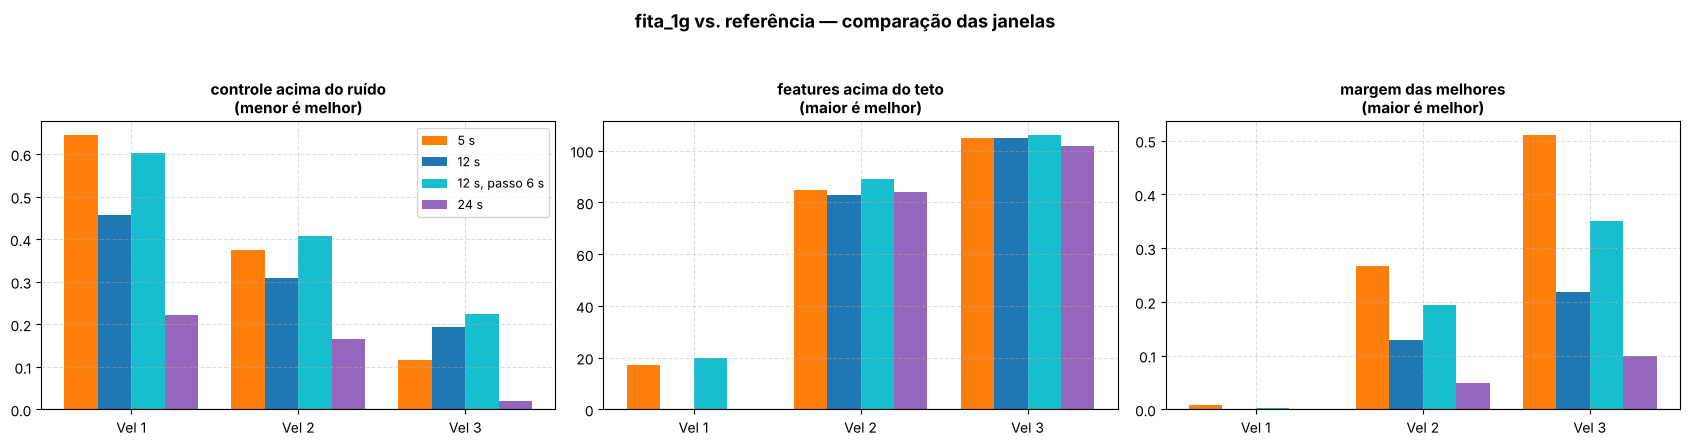

In [17]:
for condicao, comparacao in comparacoes.items():
    plotar_comparacao(comparacao, f"{condicao} vs. referência — comparação das janelas")

### Conclusões do Passo 6 (nesta execução)

**Com estas bases, a comparação de separação e controle não consegue escolher entre as janelas, por saturação.**

**1. A separação está no máximo em todas as configurações.** A coluna "separação das melhores" é **1,0** em todas as janelas e velocidades: a fita de 1 g separa do Normal **perfeitamente** nas 10 melhores features, seja com 5, 12 ou 24 s. Não há espaço para uma janela "separar melhor".

**2. Na Vel 1, o controle também está no máximo.** O teto do controle é 0,99 a 1,00 em todas as janelas: as duas metades da gravação do Normal na Vel 1 são **completamente diferentes** entre si (a deriva forte já vista no Notebook 02). Isso não depende da janela. Por isso a Vel 1 não diz nada sobre qual janela é melhor.

**3. A queda da "margem" é quase toda causada por ter menos janelas.** Exemplo na Vel 3: a margem caiu de 0,51 (5 s) para 0,22 (12 s). O teto subiu 0,29 (de 0,49 para 0,78), mas **0,22 dessa subida é só o nível de ruído** (de 0,37 para 0,59), que sobe porque 12 s tem menos da metade das janelas. A deriva real (controle acima do ruído) subiu só de 0,12 para 0,19.

**4. A janela com sobreposição é a comparação mais justa,** porque tem quase o mesmo número de janelas que a de 5 s (~90 contra ~110 por base). Ela fica **empatada**: 20, 89 e 106 features acima do teto, contra 17, 85 e 105 com 5 s.

**5. 24 s não é confiável aqui.** Com ~11 janelas em cada metade do controle, o nível de ruído vai a 0,8–0,9, perto do máximo possível (1,0). As medidas ficam "espremidas" contra o teto e não dá para interpretar.

**Em resumo:** a fita de 1 g é uma falha **forte demais** para mostrar diferença entre janelas. A diferença deve aparecer em falhas **sutis** (como desbalanceamento de 1 g ou atrito de papel), em que a variação do ciclo pode esconder a falha.

## Passo 7 — Aplicar a regra de decisão

**O que buscamos:** conferir, velocidade por velocidade, as três condições da regra fixada no início, comparando cada janela candidata com a de 5 s.

1. **Menos sensível à fase** (Passo 4): a variação conforme o ponto de início é menor em todas as bases.
2. **O controle acima do ruído não piora** (Passo 6).
3. **A margem das melhores não piora** (Passo 6).

`True` significa que a condição foi cumprida. **Leia junto com os gráficos:** uma diferença pequena (por exemplo, 0,02 na margem) pode ser só acaso com tão poucas janelas, e não deve decidir sozinha.

In [18]:
def aplicar_regra(comparacao, sensibilidade, config_candidata, config_atual=CONFIG_ATUAL):
    """Confere, velocidade por velocidade, as três condições da regra fixada antes de ver os resultados."""
    janela_candidata = dict((n, j) for n, j, _ in CONFIGURACOES)[config_candidata]
    janela_atual = dict((n, j) for n, j, _ in CONFIGURACOES)[config_atual]
    linhas = []
    for velocidade in comparacao.index.get_level_values("velocidade").unique():
        atual, candidata = comparacao.loc[(velocidade, config_atual)], comparacao.loc[(velocidade, config_candidata)]
        linhas.append({
            "velocidade": velocidade,
            "1. menos sensível à fase": None,
            "2. controle acima do ruído não piora": candidata["controle acima do ruído"] <= atual["controle acima do ruído"],
            "3. margem das melhores não piora": candidata["margem das melhores"] >= atual["margem das melhores"],
        })
    tabela = pd.DataFrame(linhas).set_index("velocidade")
    menos_sensivel = (sensibilidade[f"{janela_candidata} s"] < sensibilidade[f"{janela_atual} s"]).all()
    tabela["1. menos sensível à fase"] = menos_sensivel
    return tabela

In [19]:
for condicao, comparacao in comparacoes.items():
    for candidata in [n for n, _, _ in CONFIGURACOES if n != CONFIG_ATUAL]:
        print(f"{condicao} — {candidata} contra {CONFIG_ATUAL}:")
        display(aplicar_regra(comparacao, sensibilidade, candidata))

fita_1g — 12 s contra 5 s:


,1. menos sensível à fase,2. controle acima do ruído não piora,3. margem das melhores não piora
velocidade,,,
1,True,True,False
2,True,True,False
3,True,False,False


fita_1g — 12 s, passo 6 s contra 5 s:


,1. menos sensível à fase,2. controle acima do ruído não piora,3. margem das melhores não piora
velocidade,,,
1,True,True,False
2,True,False,False
3,True,False,False


fita_1g — 24 s contra 5 s:


,1. menos sensível à fase,2. controle acima do ruído não piora,3. margem das melhores não piora
velocidade,,,
1,True,True,False
2,True,True,False
3,True,True,False


### Decisão (nesta execução)

**Pela regra fixada antes, nenhuma janela candidata passou:** todas falham a condição 3 (margem). A própria regra manda **investigar antes de decidir**, e a investigação dos Passos 4 a 6 explica o motivo:

* **A condição 3 não pode ser cumprida com estes dados.** A separação está saturada em 1,0, e a margem cai com menos janelas por puro acaso. **Isso é uma falha do critério nestes dados, não uma prova de que 12 s é pior.** (O critério foi bem pensado para falhas sutis, mas a fita de 1 g não é sutil.)
* **A condição 1 (fase) é a única medida limpa, e favorece 12 s:** a dependência do ponto de corte cai além do esperado em 4 de 6 bases.
* **A deriva lenta da gravação aparece com janelas maiores** (autocorrelação +0,25), e é ela, não o ciclo, que domina o controle na Vel 1.

**Recomendação:**

1. **Não refazer os Notebooks 01 a 03 agora.** Manter 5 s provisoriamente, sabendo da limitação do ciclo.
2. **Reexecutar este notebook quando chegar a nova coleta**, sem mudar a regra. Ela traz o que falta aqui: falhas **sutis** (1 g, atrito), **aquecimento** antes de gravar (menos deriva) e **rodadas de Normal intercaladas**. Lá a separação não deve saturar, e a comparação passa a valer.
3. **Cronometrar a varredura nas 3 velocidades.** Os dados sugerem cerca de 9,5 s na Vel 3 e 11,5 s na Vel 2. Se o período mudar com a velocidade, a janela de 12 s ou 24 s precisa ser revista.
4. **Se a nova coleta confirmar a vantagem de 12 s,** usar **12 s com passo de 6 s**, que resolve o ciclo sem perder tantas janelas. Nesse caso, a divisão treino/teste precisa ser por blocos de tempo.

## O que conferir antes de seguir

* [ ] **Passo 3:** o número de janelas por base de cada configuração está anotado.
* [ ] **Passo 4:** você viu no gráfico se a janela de 12 s deixou de "ondular".
* [ ] **Passo 5:** a variação do Normal caiu mais do que o esperado só pelo tamanho da janela?
* [ ] **Passo 6:** o controle ficou mais perto do ruído, e a margem se manteve?
* [ ] **Passo 7:** a janela escolhida está anotada, com o motivo.

**Próximo passo:** trocar `JANELA_S` nos Notebooks 01, 02 e 03 pela janela escolhida, reexecutar e atualizar as conclusões.